# 05 · Acumulación, mesada y reglas de AFP y Colpensiones

Componentes del paso 6:

1. `decumulation`: capital necesario por peso de mesada (RV08, 13 mesadas, tasa técnica real).
2. `accumulation`: saldo de la cuenta individual mes a mes.
3. `regimes`: reglas de la Ley 100 en las AFP (capital suficiente, garantía de pensión mínima, devolución de saldos) y en Colpensiones (tasa de reemplazo del art. 34, indemnización sustitutiva).

Al final se conectan con los modelos de los pasos 3 a 5 para cuatro perfiles de ejemplo, todos cotizando hoy. Es una versión preliminar: el motor formal, con métricas y sensibilidad, es el paso 7.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from pension_mc import accumulation as A, decumulation as D, regimes as G, returns as R
from pension_mc import wages as W, contributions as C
from pension_mc.config import parametros

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "legend.frameon": False,
    "lines.linewidth": 2, "figure.figsize": (9, 4.2), "figure.dpi": 110, "font.size": 10,
})
P = parametros()
SMMLV = P["smmlv"]["valores"][2026]
SEM_MES = P["supuestos"]["semanas_por_mes"]
print(f"SMMLV 2026: ${SMMLV:,.0f}; tasa técnica real: {P['supuestos']['tasa_tecnica_real']:.0%}; "
      f"crecimiento real del SMMLV: {P['supuestos']['crecimiento_real_smmlv']:.0%}")

SMMLV 2026: $1,750,905; tasa técnica real: 4%; crecimiento real del SMMLV: 1%


## 1. ¿Cuánto capital necesita una mesada?

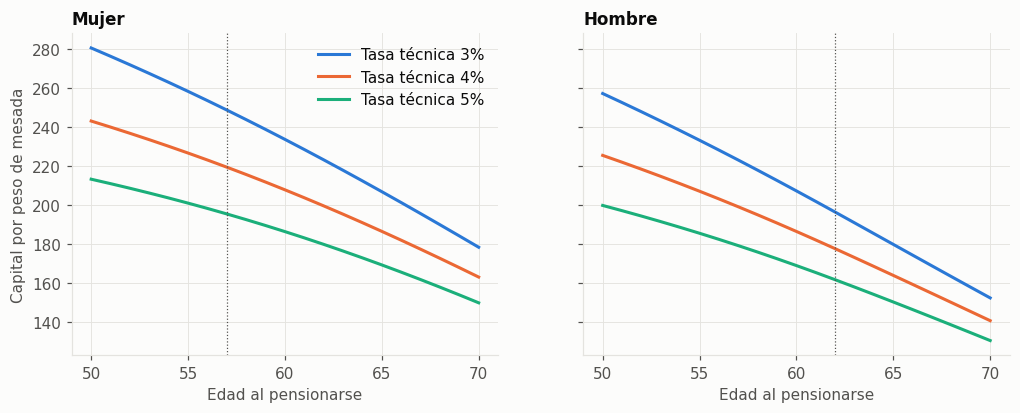

,IPC (pensión > mínimo),crece con el SMMLV (+1 %),"crece +2,4 % (parámetro oficial)",con cónyuge 3 años distinto
perfil,,,,
"Mujer, 57 años",384,437,530,413
"Hombre, 62 años",311,345,402,400


In [2]:
edades = np.arange(50, 71)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, sexo in zip(axes, ["Mujer", "Hombre"]):
    for j, i in enumerate([0.03, 0.04, 0.05]):
        f = [D.factor_anualidad(float(e), sexo, i) for e in edades]
        ax.plot(edades, f, color=SERIES[j], label=f"Tasa técnica {i:.0%}")
    ax.axvline(G.edad_pension("rais", sexo), color=INK2, lw=0.8, ls=":")
    ax.set_title(sexo, fontsize=11)
    ax.set_xlabel("Edad al pensionarse")
    ax.xaxis.set_major_locator(mtick.MultipleLocator(5))
axes[0].set_ylabel("Capital por peso de mesada")
axes[0].legend(loc="upper right")
plt.show()

filas = []
for sexo, edad, conyuge in [("Mujer", 57, ("Hombre", 60)), ("Hombre", 62, ("Mujer", 59))]:
    filas.append({"perfil": f"{sexo}, {edad} años",
                  "IPC (pensión > mínimo)": D.factor_anualidad(edad, sexo),
                  "crece con el SMMLV (+1 %)": D.factor_anualidad(edad, sexo, crecimiento=0.01),
                  "crece +2,4 % (parámetro oficial)": D.factor_anualidad(edad, sexo, crecimiento=0.0239),
                  "con cónyuge 3 años distinto": D.factor_anualidad(edad, sexo, conyuge=conyuge)})
fac = pd.DataFrame(filas).set_index("perfil")
(fac * SMMLV / 1e6).style.format("{:,.0f}").set_caption("Millones de pesos de 2026 para financiar 1 SMMLV de por vida (tasa técnica 4 %)")

- Una mujer que se pensiona a los 57 años necesita unos **384 millones de pesos de 2026** para financiar un salario mínimo vitalicio indexado al IPC. Si la mesada crece con el SMMLV, que es lo que pasa con una pensión mínima, necesita **437 millones**. Un hombre a los 62 necesita 311 y 345 millones.
- El parámetro oficial de crecimiento de las pensiones mínimas (Res. 3099 de 2015, modificada en 2026: brecha promedio entre el aumento del mínimo y el IPC en 12 años) es de ~2,4 % real y eleva el capital necesario otro 17–21 %.
- Un cónyuge beneficiario encarece la pensión de los hombres en ~29 % (la esposa suele ser más joven y vivir más). Este modelo no incluye beneficiarios por defecto, así que es una cota superior de la mesada.

## 2. Tasa de reemplazo en Colpensiones (art. 34)

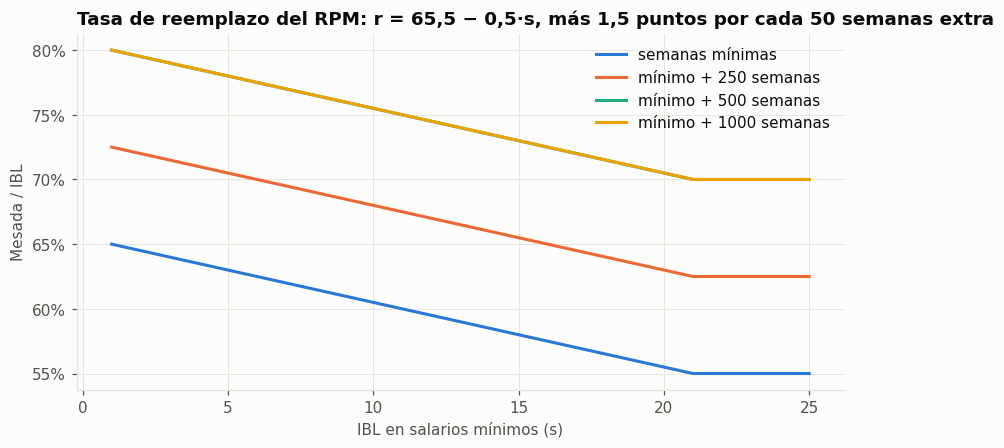

In [3]:
s = np.linspace(1, 25, 200)
fig, ax = plt.subplots()
for j, extra in enumerate([0, 250, 500, 1000]):
    t = G.tasa_reemplazo_rpm(s, np.full_like(s, 1300 + extra), 1300, 1.0)
    ax.plot(s, t, color=SERIES[j], label=f"mínimo + {extra} semanas" if extra else "semanas mínimas")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("IBL en salarios mínimos (s)")
ax.set_ylabel("Mesada / IBL")
ax.set_title("Tasa de reemplazo del RPM: r = 65,5 − 0,5·s, más 1,5 puntos por cada 50 semanas extra")
ax.legend(loc="upper right")
plt.show()

Para alguien con IBL de 1 SMMLV, la tasa de reemplazo sobre el IBL es 65 %, pero la pensión no puede ser menor que el mínimo: en la práctica recibe el 100 %. Por eso el RPM es muy favorable para salarios bajos, siempre que se alcancen las semanas.

## 3. Verificación determinista

Un hombre que cotiza todos los meses desde los 25 hasta los 62 años sobre 3 SMMLV constantes, con rentabilidad real del 3 % y SMMLV constante. El saldo y la mesada se pueden calcular a mano.

In [4]:
n = (62 - 25) * 12
ibc = np.full((1, n), 3 * SMMLV)
r = np.full((1, n), 1.03 ** (1 / 12) - 1)
saldo = A.saldo(A.aportes(ibc, np.ones((1, n), bool)), r)[0, -1]
rm = 1.03 ** (1 / 12) - 1
a_mano = 0.115 * 3 * SMMLV * ((1 + rm) ** n - 1) / rm
res = G.rais(np.array([saldo]), np.array([n * SEM_MES]), edad=62, sexo="Hombre", anio=2063, smmlv=SMMLV, crecimiento_smmlv=0.0)
rp = G.rpm(ibc, np.ones((1, n), bool), edad=62, sexo="Hombre", anio=2063, smmlv=SMMLV)
pd.Series({"saldo simulado (millones)": saldo / 1e6, "saldo a mano (millones)": a_mano / 1e6,
           "estado AFP": res.estado.iloc[0], "mesada AFP (SMMLV)": res.mesada.iloc[0] / SMMLV,
           "mesada AFP / salario": res.mesada.iloc[0] / (3 * SMMLV),
           "mesada Colpensiones (SMMLV)": rp.mesada.iloc[0] / SMMLV,
           "mesada Colpensiones / salario": rp.mesada.iloc[0] / (3 * SMMLV)}).to_frame("valor")

,valor
saldo simulado (millones),486.24058
saldo a mano (millones),486.24058
estado AFP,capital_suficiente
mesada AFP (SMMLV),1.563378
mesada AFP / salario,0.521126
mesada Colpensiones (SMMLV),2.37
mesada Colpensiones / salario,0.79


El saldo simulado coincide al peso con el cálculo a mano. Con 37 años de cotización continua y 3 % real, la cuenta individual paga ~1,6 SMMLV (tasa de reemplazo del 52 %). Colpensiones pagaría ~2,4 SMMLV (79 %: con más de 1.900 semanas llega al tope de +15 puntos). Para salarios medios, el RPM es más generoso que lo que financia el ahorro: esa diferencia es el subsidio implícito del régimen de prima media, que la reforma pensional limita a la parte del salario hasta 2,3 SMMLV.

## 4. Perfiles de ejemplo (versión preliminar del motor)

Cada simulación combina:
- salarios (paso 4), condicionados en el salario actual;
- meses cotizados (paso 5), condicionados en las semanas ya cotizadas;
- rentabilidades de Protección con la trayectoria de multifondos por defecto (paso 3).

Luego aplica las reglas de las AFP y de Colpensiones a **la misma población simulada**.

In [5]:
MS, MC = W.ModeloSalarial.cargar(), C.ModeloCotizacion.cargar()
HIST = R.historico("Protección")

def simular_perfil(edad, sexo, educ, salario, semanas=0.0, saldo=0.0, cotiza_hoy=None, n_sims=5_000, seed=0):
    edad_pen = G.edad_pension("rais", sexo)
    n_anios = edad_pen - edad
    n_meses = 12 * n_anios
    anio_pension = 2026 + n_anios
    smmlv = W.smmlv_real(n_anios + 1)
    sal = np.maximum(MS.simular(edad, sexo, educ, n_anios, n_sims, salario_actual=salario,
                                smmlv_actual=SMMLV, seed=seed), smmlv[:-1])
    ibc = A.mensualizar(W.ibc(sal, smmlv[:-1]))
    if semanas > 0 or cotiza_hoy is not None:
        eta, est = MC.condicionar(edad, sexo, educ, semanas, n_sims, cotiza_hoy=cotiza_hoy, seed=seed)
    else:
        eta, est = None, None
    cot = MC.simular(edad, sexo, educ, n_meses, n_sims, eta=eta, estado_inicial=est, seed=seed + 1)
    rent = R.bootstrap_estacionario(HIST, n_sims, n_meses, seed=seed + 2)
    r = rent.portafolio(R.pesos_por_defecto(edad, sexo, n_meses))
    s = A.saldo(A.aportes(ibc, cot), r, saldo)[:, -1]
    sem = semanas + cot.sum(axis=1) * SEM_MES
    ultimo = sal[:, -10:].mean(axis=1)
    afp = G.rais(s, sem, edad=edad_pen, sexo=sexo, anio=anio_pension, smmlv=smmlv[-1])
    col = G.rpm(ibc, cot, edad=edad_pen, sexo=sexo, anio=anio_pension, smmlv=smmlv[-1], semanas_previas=semanas)
    for d in (afp, col):
        d["mesada_smmlv"] = d["mesada"] / smmlv[-1]
        d["reemplazo"] = d["mesada"] / ultimo
    return afp, col, smmlv[-1]

def saldo_aproximado(semanas, salario, rentabilidad_acumulada=1.25):
    """Saldo actual aproximado si la persona no lo conoce: aportes del 11,5 % más rendimientos."""
    return 0.115 * salario * semanas / SEM_MES * rentabilidad_acumulada

PERFILES = {
    "Mujer, 25, superior, 2 SMMLV, 100 sem.": dict(edad=25, sexo="Mujer", educ="Superior", salario=2 * SMMLV, semanas=100,
                                                   saldo=saldo_aproximado(100, 2 * SMMLV), cotiza_hoy=True),
    "Hombre, 25, media, 1 SMMLV, 100 sem.": dict(edad=25, sexo="Hombre", educ="Media", salario=SMMLV, semanas=100,
                                                 saldo=saldo_aproximado(100, SMMLV), cotiza_hoy=True),
    "Mujer, 40, media, 1 SMMLV, 500 sem.": dict(edad=40, sexo="Mujer", educ="Media", salario=SMMLV, semanas=500,
                                                 saldo=saldo_aproximado(500, SMMLV), cotiza_hoy=True),
    "Hombre, 45, superior, 4 SMMLV, 900 sem.": dict(edad=45, sexo="Hombre", educ="Superior", salario=4 * SMMLV, semanas=900,
                                                     saldo=saldo_aproximado(900, 4 * SMMLV), cotiza_hoy=True),
}
res = {k: simular_perfil(**v) for k, v in PERFILES.items()}
filas = []
for k, (afp, col, sm) in res.items():
    pen = afp[afp.estado != "devolucion"]
    filas.append({
        "perfil": k,
        "AFP: capital suficiente": (afp.estado == "capital_suficiente").mean(),
        "AFP: garantía mínima": (afp.estado == "garantia_minima").mean(),
        "AFP: devolución": (afp.estado == "devolucion").mean(),
        "AFP: mesada mediana si se pensiona (SMMLV)": pen.mesada_smmlv.median() if len(pen) else np.nan,
        "AFP: reemplazo mediano si se pensiona": pen.reemplazo.median() if len(pen) else np.nan,
        "Colpensiones: se pensiona": (col.estado == "pension").mean(),
        "Colpensiones: mesada mediana (SMMLV)": col[col.estado == "pension"].mesada_smmlv.median(),
    })
tab = pd.DataFrame(filas).set_index("perfil")
fmt = {c: "{:.0%}" for c in tab.columns}
fmt.update({c: "{:.2f}" for c in tab.columns if "SMMLV" in c})
tab.style.format(fmt, na_rep="—")

,AFP: capital suficiente,AFP: garantía mínima,AFP: devolución,AFP: mesada mediana si se pensiona (SMMLV),AFP: reemplazo mediano si se pensiona,Colpensiones: se pensiona,Colpensiones: mesada mediana (SMMLV)
perfil,,,,,,,
"Mujer, 25, superior, 2 SMMLV, 100 sem.",24%,76%,0%,1.00,46%,100%,1.96
"Hombre, 25, media, 1 SMMLV, 100 sem.",1%,93%,6%,1.00,106%,84%,1.00
"Mujer, 40, media, 1 SMMLV, 500 sem.",0%,52%,48%,1.00,106%,52%,1.00
"Hombre, 45, superior, 4 SMMLV, 900 sem.",87%,13%,0%,1.56,43%,93%,2.56


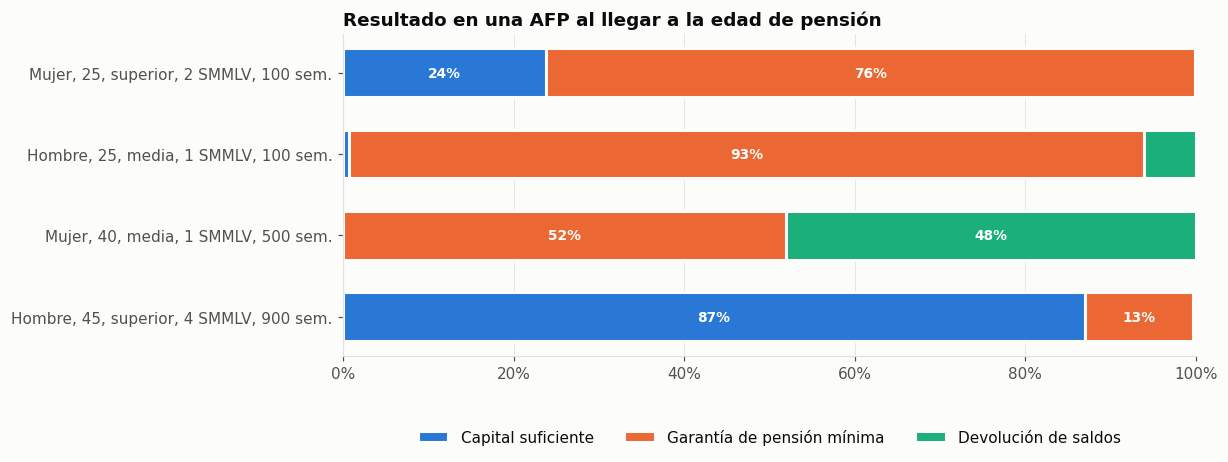

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.8))
nombres = list(res)
y = np.arange(len(nombres))
izq = np.zeros(len(nombres))
etiquetas = {"capital_suficiente": "Capital suficiente", "garantia_minima": "Garantía de pensión mínima", "devolucion": "Devolución de saldos"}
for j, est in enumerate(G.ESTADOS_RAIS):
    v = np.array([(res[k][0].estado == est).mean() for k in nombres])
    ax.barh(y, v, left=izq, color=SERIES[j], edgecolor=SURFACE, linewidth=2, label=etiquetas[est], height=0.6)
    for yi, (l, w) in enumerate(zip(izq, v)):
        if w >= 0.07:
            ax.text(l + w / 2, yi, f"{w:.0%}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    izq += v
ax.set_yticks(y, nombres)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_title("Resultado en una AFP al llegar a la edad de pensión")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncols=3)
plt.show()

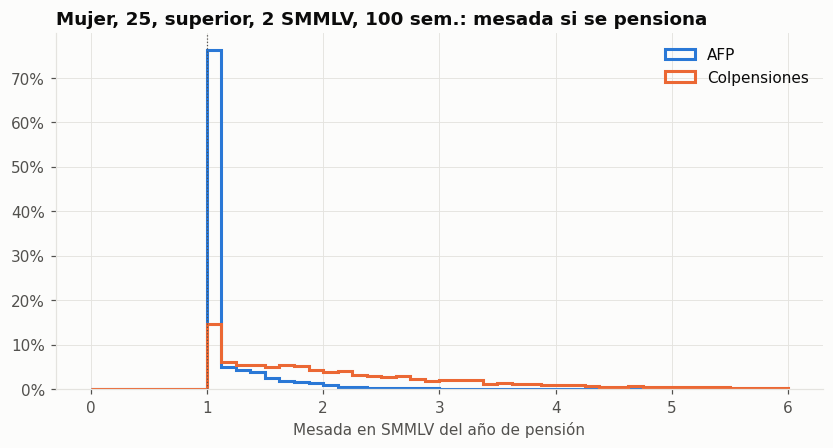

In [7]:
k = "Mujer, 25, superior, 2 SMMLV, 100 sem."
afp, col, sm = res[k]
fig, ax = plt.subplots()
bins = np.linspace(0, 6, 49)
ax.hist(afp[afp.estado != "devolucion"].mesada_smmlv, bins=bins, histtype="step", lw=2, color=SERIES[0],
        weights=np.full((afp.estado != "devolucion").sum(), 1 / len(afp)), label="AFP")
ax.hist(col[col.estado == "pension"].mesada_smmlv, bins=bins, histtype="step", lw=2, color=SERIES[1],
        weights=np.full((col.estado == "pension").sum(), 1 / len(col)), label="Colpensiones")
ax.axvline(1, color=INK2, lw=0.8, ls=":")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Mesada en SMMLV del año de pensión")
ax.set_title(f"{k}: mesada si se pensiona")
ax.legend(loc="upper right")
plt.show()

## Hallazgos

1. **El capital necesario es muy alto frente a lo que acumula un salario mínimo.** Financiar 1 SMMLV vitalicio a los 57 años (mujer) cuesta ~440 millones de pesos de 2026. Un trabajador de salario mínimo que cotiza 1.000–1.300 semanas acumula una fracción de eso. Quien gana el mínimo **depende casi por completo de la garantía de pensión mínima**, y por eso de las semanas.
2. **En las AFP, la pregunta clave no es la rentabilidad sino las semanas.** Para los perfiles de salario bajo el resultado es binario: garantía mínima (1 SMMLV) si alcanza las semanas, devolución de saldos si no.
3. **Colpensiones es más generoso para salarios bajos y medios que cumplen las semanas.** La tasa de reemplazo del art. 34 (55–80 % del IBL, con piso de 1 SMMLV) supera lo que financia el ahorro individual con rentabilidades realistas. Es el subsidio implícito del RPM.
4. **Las mujeres con salarios medios quedan en la pensión mínima en las AFP.** Una mujer de 25 años con educación superior que gana 2 SMMLV y cotiza de forma estable alcanza las semanas con certeza, pero a los 57 años su saldo solo financia más de 1 SMMLV en el 24 % de los casos; el 76 % recibe la garantía mínima. Con ~30 años de vida esperada desde los 57, cada peso de mesada cuesta mucho. En Colpensiones recibiría ~2 SMMLV. **La edad de retiro será una palanca clave en el paso 7.**
5. **Para el salario mínimo, la AFP puede pensionar a más gente que Colpensiones.** Ambos pagan 1 SMMLV, pero la garantía de pensión mínima exige a los hombres 1.150 semanas y Colpensiones 1.300: el hombre de 25 años con educación media se pensiona en el 94 % de los casos en la AFP y en el 84 % en Colpensiones.
6. **La historia importa:** a los 40 años, la mujer con 500 semanas tiene ~50 % de probabilidad de pensionarse; el hombre de 45 con 900 semanas y 4 SMMLV, casi 100 %.

**Simplificaciones de este paso:**
- Sin beneficiarios, así que la mesada es una cota superior.
- La renta vitalicia se valora a la tasa técnica; no se modela el retiro programado año a año.
- No hay bono pensional ni traslados entre regímenes.
- Para perfiles con historia, el saldo actual se aproxima con las semanas, y el IBL de Colpensiones usa solo el periodo simulado.
- La comparación AFP vs. Colpensiones aplica ambas reglas a la misma población, aunque en la realidad cada persona está en un solo régimen.